In [35]:
%matplotlib inline

import pandas as pd
from torchvision import models
import numpy as np
import torch
import torch.nn as nn
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt
import random
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
import tqdm
import torch.optim as optim
from tqdm import tqdm
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

#Data Prepare

Creates the augmented datset images and saves to file

In [36]:
data_dir  = 'garbage_classification'

classes = os.listdir(data_dir)
print(classes)

['glass', 'metal', 'paper', 'plastic']


In [37]:
random_seed = 42
torch.manual_seed(random_seed)

In [38]:
BATCH_SIZE = 32
data_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop(227),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

dataset = datasets.ImageFolder(root='garbage_classification', transform=data_transform)

print(f"Classes found: {dataset.classes}")
print(f"Total images: {len(dataset)}")

Classes found: ['glass', 'metal', 'paper', 'plastic']
Total images: 4695


--- VISUALIZING AUGMENTED TRAINING DATA ---
Batch Shape: torch.Size([32, 3, 227, 227])
Labels in batch: tensor([0, 2, 0, 2, 0, 3, 1, 3, 0, 1, 3, 2, 2, 0, 0, 0, 2, 0, 0, 0, 0, 1, 0, 0,
        3, 2, 2, 2, 2, 0, 0, 0])


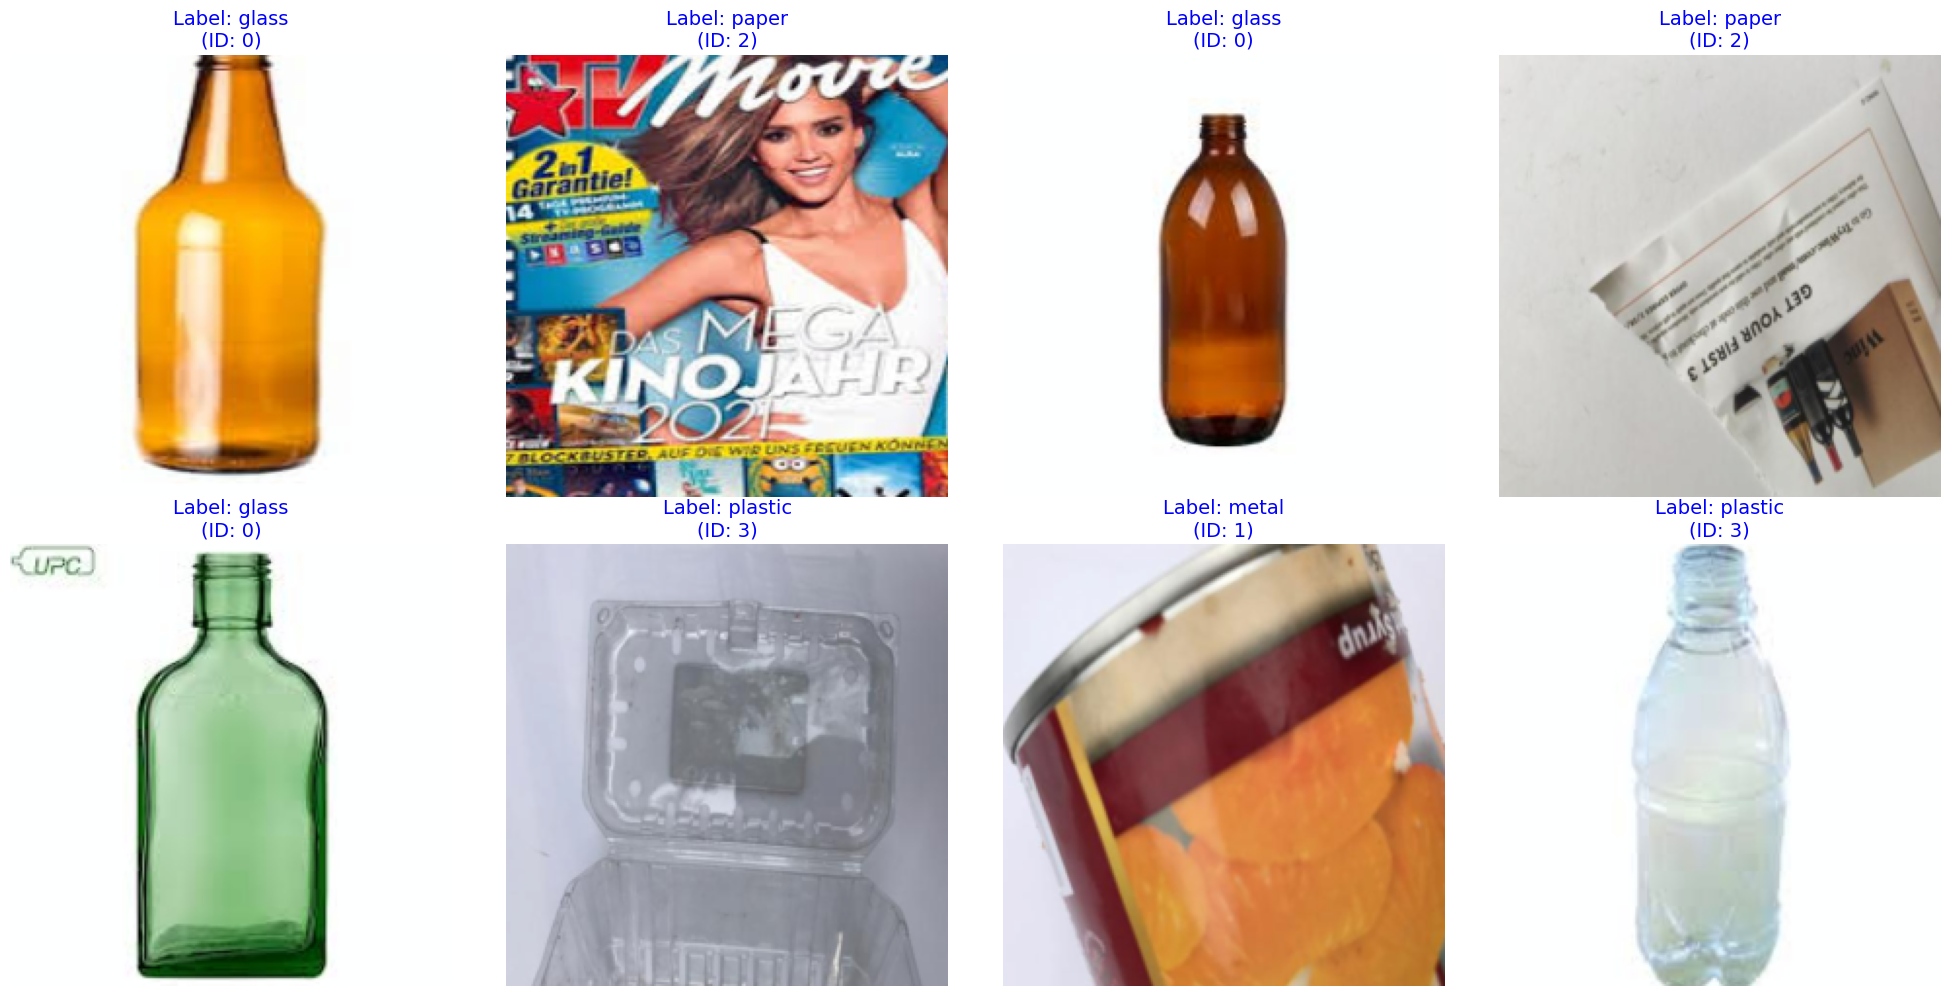

In [47]:
import matplotlib.pyplot as plt
import numpy as np

def visualize_augmented_batch(loader, classes, count=8):
    dataiter = iter(loader)
    images, labels = next(dataiter)

    print(f"Batch Shape: {images.shape}")
    print(f"Labels in batch: {labels}")

    fig = plt.figure(figsize=(20, 10))

    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    for i in range(min(count, len(images))):
        ax = fig.add_subplot(2, 4, i+1)

        img = images[i].permute(1, 2, 0).cpu().numpy()

        img = std * img + mean

        img = np.clip(img, 0, 1)

        ax.imshow(img)

        label_idx = labels[i].item()
        if label_idx < len(classes):
            label_name = classes[label_idx]
        else:
            label_name = f"INVALID INDEX {label_idx}"

        ax.set_title(f"Label: {label_name}\n(ID: {label_idx})", fontsize=14, color='blue')
        ax.axis('off')

    plt.tight_layout()
    plt.show()

print("--- VISUALIZING AUGMENTED TRAINING DATA ---")
visualize_augmented_batch(train_dl, dataset.classes, count=8)

In [39]:
train_ds , val_ds , test_ds = torch.utils.data.random_split(dataset, [3200, 395, 1100])

train_dl = DataLoader(train_ds, batch_size=32, shuffle=True)
val_dl = DataLoader(val_ds, batch_size=32, shuffle=False)
test_dl = DataLoader(test_ds, batch_size=32, shuffle=False)

In [40]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class RecyclingCNN(nn.Module):
    def __init__(self, num_classes=4):
        super(RecyclingCNN, self).__init__()

        self.conv1 = nn.Conv2d(in_channels=3, out_channels=96, kernel_size=11, stride=4, padding=0)
        self.bn1 = nn.BatchNorm2d(96)
        self.pool1 = nn.MaxPool2d(kernel_size=3, stride=2)

        self.conv2 = nn.Conv2d(in_channels=96, out_channels=256, kernel_size=5, stride=1, padding='same')
        self.bn2 = nn.BatchNorm2d(256)
        self.pool2 = nn.MaxPool2d(kernel_size=3, stride=2)

        self.conv3 = nn.Conv2d(in_channels=256, out_channels=256, kernel_size=3, stride=1, padding='same')
        self.pool3 = nn.MaxPool2d(kernel_size=3, stride=2)

        self.fc1 = nn.Linear(9216, 9216)
        self.fc2 = nn.Linear(9216, 4096)
        self.fc3 = nn.Linear(4096, 4096)

        self.classifier = nn.Linear(4096, num_classes)

    def forward(self, x):
        x = self.conv1(x)
        x = F.relu(x)
        x = self.pool1(x)
        x = self.bn1(x)

        x = self.conv2(x)
        x = F.relu(x)
        x = self.pool2(x)
        x = self.bn2(x)

        x = self.conv3(x)
        x = F.relu(x)
        x = self.pool3(x)

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))

        x = self.classifier(x)
        return x

In [41]:
class UnNormalize(object):
    def __init__(self, mean, std):
        self.mean = mean
        self.std = std

    def __call__(self, tensor):
        for t, m, s in zip(tensor, self.mean, self.std):
            t.mul_(s).add_(m)
        return tensor

unorm = UnNormalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))

In [42]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = RecyclingCNN(num_classes=4).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print(f"Model created on {device} expecting 227x227 inputs.")

Model created on cuda expecting 227x227 inputs.


In [43]:
def train_one_epoch(model, loader, optimizer, epoch, scaler):
    model.train()
    running_loss = 0.0
    loop = tqdm(loader, desc=f"Epoch {epoch} [Train]")

    for r_img, targets in loop:
        r_img = r_img.to(device)
        targets = targets.to(device)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast('cuda'):
            outputs = model(r_img)

            loss = criterion(outputs, targets)

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=0.1)

        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()
        loop.set_postfix(loss=loss.item())

    return running_loss / len(loader)

def validate(model, loader):
    model.eval()
    running_loss = 0.0

    with torch.no_grad():
        for r_img, targets in loader:
            r_img = r_img.to(device)
            targets = targets.to(device)

            with torch.amp.autocast('cuda'):
                outputs = model(r_img)
                loss = criterion(outputs, targets)

            running_loss += loss.item()

    return running_loss / len(loader)

In [44]:
def evaluate_model(model, loader, device, classes, title="Model Evaluation"):
    model.eval()
    y_true = []
    y_pred = []

    print("Gathering predictions...")
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average='weighted')

    print("\n" + "="*40)
    print(f"  {title.upper()} REPORT")
    print("="*40)
    print(f"Global Accuracy: {acc:.2%}")
    print(f"Global F1 Score: {f1:.4f}")
    print("-" * 40)

    print("Classification Report:\n")
    report_dict = classification_report(y_true, y_pred, target_names=classes, output_dict=True)
    print(classification_report(y_true, y_pred, target_names=classes))

    fig, axes = plt.subplots(1, 2, figsize=(18, 7))

    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=classes, yticklabels=classes, ax=axes[0])
    axes[0].set_title('Confusion Matrix')
    axes[0].set_xlabel('Predicted Label')
    axes[0].set_ylabel('True Label')

    class_names = []
    class_scores = []
    for cls in classes:
        class_names.append(cls)
        class_scores.append(report_dict[cls]['f1-score'])

    sns.barplot(x=class_names, y=class_scores, palette='viridis', ax=axes[1])
    axes[1].set_title('F1 Score per Class')
    axes[1].set_ylim(0, 1.0)
    axes[1].set_ylabel('F1 Score')

    for i, v in enumerate(class_scores):
        axes[1].text(i, v + 0.01, f"{v:.2f}", ha='center', fontweight='bold')

    plt.tight_layout()
    plt.show()

    return {
        "accuracy": acc,
        "f1": f1,
        "y_true": y_true,
        "y_pred": y_pred
    }

def load_model(checkpoint_path, model):
    checkpoint = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(checkpoint, strict=True)
    model.to(device)
    model.eval()

    for param in model.parameters():
        param.requires_grad = False
    return model

In [45]:
def plot_history(history):
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history['train_loss'], label='Train Loss')
    plt.plot(history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.show()

In [46]:
model_1 = RecyclingCNN(num_classes=4).to(device)

optimizer = optim.AdamW(params=model_1.parameters(),lr=0.001, weight_decay=1e-4)
scaler = torch.cuda.amp.GradScaler()
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=10)

EPOCHS = 150
best_loss = float('inf')
early_stopping_counter=0
history=[]
for epoch in range(1, EPOCHS + 1):
    train_loss = train_one_epoch(model_1, train_dl, optimizer, epoch, scaler)

    val_loss = validate(model_1, val_dl)

    scheduler.step(val_loss)

    print(f"Epoch {epoch}/{EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

    history.append([train_loss, val_loss])

    if val_loss < best_loss:
        best_loss = val_loss
        early_stopping_counter = 0
        torch.save(model_1.state_dict(), "model_non_augmented_base.pth")
        print("✓ Saved best model")
    else:
        early_stopping_counter += 1
        if early_stopping_counter >= 15:
            print("Early stopping triggered.")
            break

print("Training Complete.")

C:\Users\deniz\AppData\Local\Temp\ipykernel_24088\1277765694.py:4: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
Epoch 1 [Train]: 100%|██████████| 100/100 [00:17<00:00,  5.61it/s, loss=1.05]


Epoch 1/150 | Train Loss: 11.2795 | Val Loss: 1.2550
✓ Saved best model


Epoch 2 [Train]: 100%|██████████| 100/100 [00:16<00:00,  6.19it/s, loss=0.917]


Epoch 2/150 | Train Loss: 1.0672 | Val Loss: 0.8918
✓ Saved best model


Epoch 3 [Train]: 100%|██████████| 100/100 [00:16<00:00,  6.24it/s, loss=0.964]


Epoch 3/150 | Train Loss: 0.9582 | Val Loss: 0.8604
✓ Saved best model


... (44 outputs left out)

Epoch 26 [Train]: 100%|██████████| 100/100 [00:17<00:00,  5.57it/s, loss=0.0421] 


Epoch 26/150 | Train Loss: 0.0859 | Val Loss: 2.2509


Epoch 27 [Train]: 100%|██████████| 100/100 [00:17<00:00,  5.64it/s, loss=0.0446] 


Epoch 27/150 | Train Loss: 0.0824 | Val Loss: 1.8703
Early stopping triggered.
Training Complete.


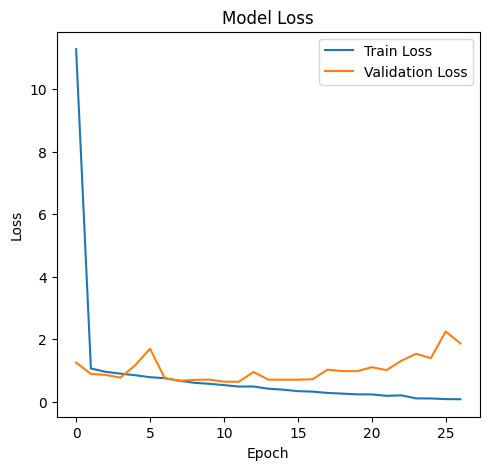

Gathering predictions...

  MODEL EVALUATION REPORT
Global Accuracy: 76.18%
Global F1 Score: 0.7606
----------------------------------------
Classification Report:

              precision    recall  f1-score   support

       glass       0.80      0.86      0.83       458
       metal       0.58      0.74      0.65       177
       paper       0.83      0.79      0.81       238
     plastic       0.82      0.56      0.67       227

    accuracy                           0.76      1100
   macro avg       0.76      0.74      0.74      1100
weighted avg       0.77      0.76      0.76      1100



C:\Users\deniz\AppData\Local\Temp\ipykernel_37040\910868668.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_names, y=class_scores, palette='viridis', ax=axes[1])


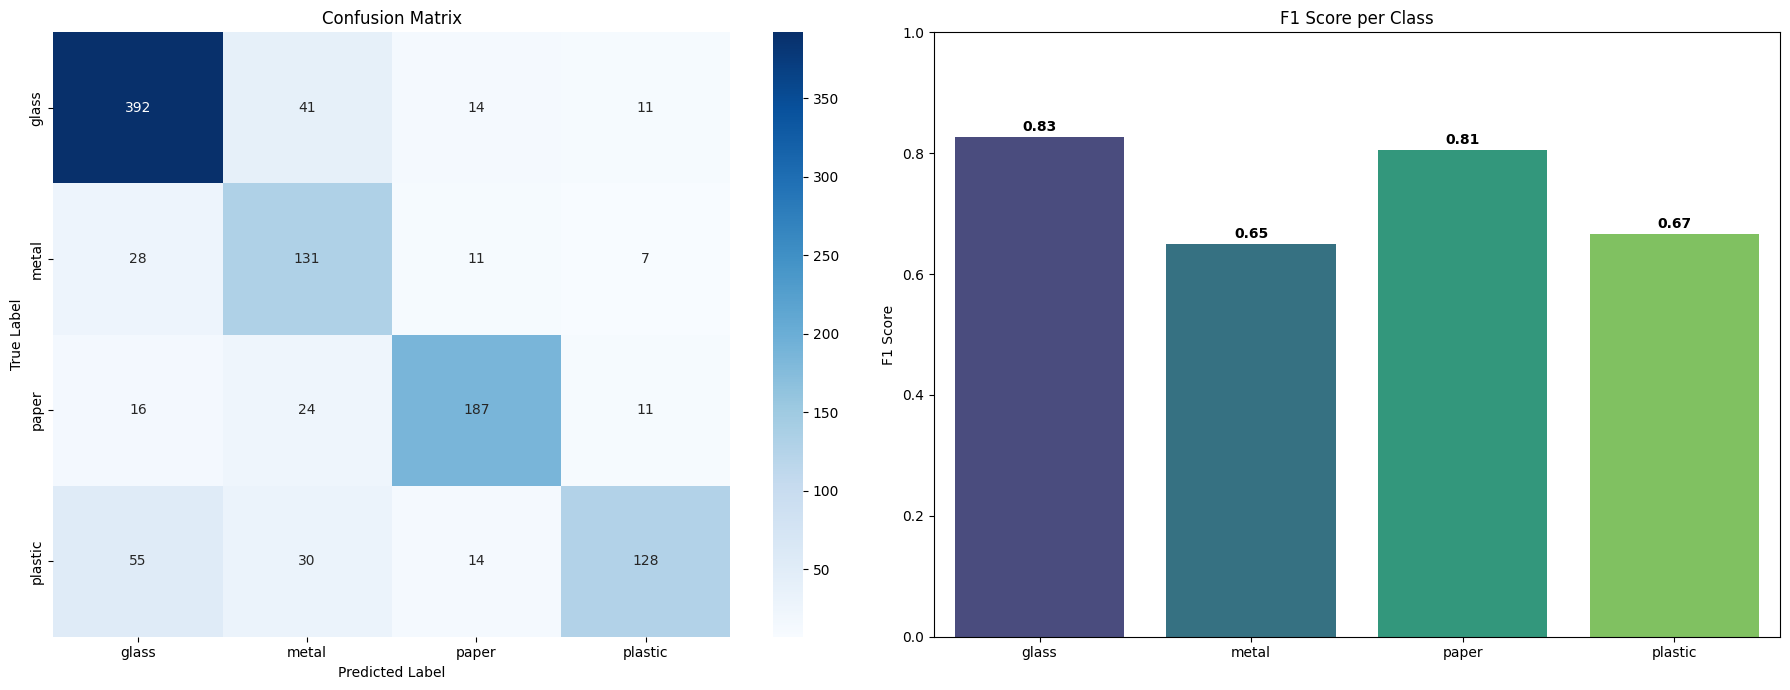

In [116]:
plot_history({
    'train_loss': [x[0] for x in history],
    'val_loss': [x[1] for x in history],
    'train_acc': [],
    'val_acc': []
})
model_1 = RecyclingCNN(num_classes=4).to(device)
model_loaded = load_model("model_non_augmented_base.pth", model_1)
metrics = evaluate_model(model_loaded, test_dl, device, dataset.classes)

In [13]:
class RecyclingVGG(nn.Module):
    def __init__(self, num_classes=4, pre_trained=True):
        super(RecyclingVGG, self).__init__()

        weights = models.VGG16_Weights.DEFAULT if pre_trained else None
        self.model = models.vgg16(weights=weights)

        for param in self.model.features.parameters():
            param.requires_grad = False

        num_features = self.model.classifier[6].in_features
        self.model.classifier[6] = nn.Linear(num_features, num_classes)

    def forward(self, x):
        return self.model(x)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_1 = RecyclingVGG(num_classes=4).to(device)
optimizer = optim.AdamW(params=model_1.parameters(),lr=0.0005, weight_decay=1e-4)
scaler = torch.cuda.amp.GradScaler()
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=10)

EPOCHS = 150
best_loss = float('inf')
early_stopping_counter = 0
history=[]
for epoch in range(1, EPOCHS + 1):
    train_loss = train_one_epoch(model_1, train_dl, optimizer, epoch, scaler)

    val_loss = validate(model_1, val_dl)

    scheduler.step(val_loss)

    print(f"Epoch {epoch}/{EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

    history.append([train_loss, val_loss])

    if val_loss < best_loss:
        best_loss = val_loss
        early_stopping_counter = 0
        torch.save(model_1.state_dict(), "model_non_augmented_vgg.pth")
        print("✓ Saved best model")
    else:
        early_stopping_counter += 1
        if early_stopping_counter >= 15:
            print("Early stopping triggered.")
            break

print("Training Complete.")

C:\Users\deniz\AppData\Local\Temp\ipykernel_37040\607819854.py:4: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
Epoch 1 [Train]: 100%|██████████| 100/100 [04:40<00:00,  2.80s/it, loss=0.218]


Epoch 1/150 | Train Loss: 0.8993 | Val Loss: 0.7034
✓ Saved best model


Epoch 2 [Train]: 100%|██████████| 100/100 [04:45<00:00,  2.85s/it, loss=1.54] 


Epoch 2/150 | Train Loss: 0.7222 | Val Loss: 1.1694


Epoch 3 [Train]: 100%|██████████| 100/100 [04:44<00:00,  2.85s/it, loss=0.624] 


Epoch 3/150 | Train Loss: 0.6073 | Val Loss: 1.2805


... (8 outputs left out)

Epoch 8 [Train]: 100%|██████████| 100/100 [05:12<00:00,  3.13s/it, loss=0]      


Epoch 8/150 | Train Loss: 0.5128 | Val Loss: 4.8924


Epoch 9 [Train]:  75%|███████▌  | 75/100 [03:54<01:18,  3.13s/it, loss=0.00264] 


KeyboardInterrupt: 

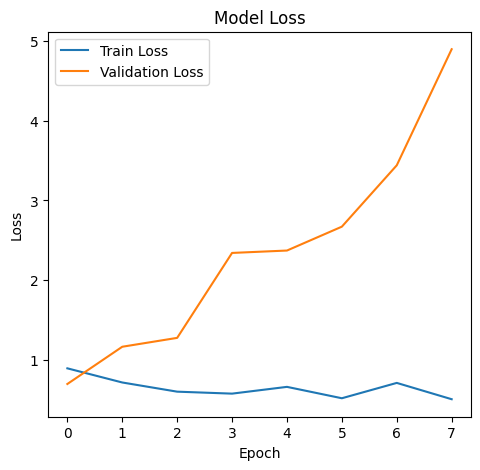

Gathering predictions...

  MODEL EVALUATION REPORT
Global Accuracy: 82.09%
Global F1 Score: 0.8149
----------------------------------------
Classification Report:

              precision    recall  f1-score   support

       glass       0.84      0.86      0.85       458
       metal       0.64      0.88      0.74       177
       paper       0.91      0.98      0.95       238
     plastic       0.94      0.52      0.67       227

    accuracy                           0.82      1100
   macro avg       0.83      0.81      0.80      1100
weighted avg       0.84      0.82      0.81      1100



C:\Users\deniz\AppData\Local\Temp\ipykernel_37040\910868668.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_names, y=class_scores, palette='viridis', ax=axes[1])


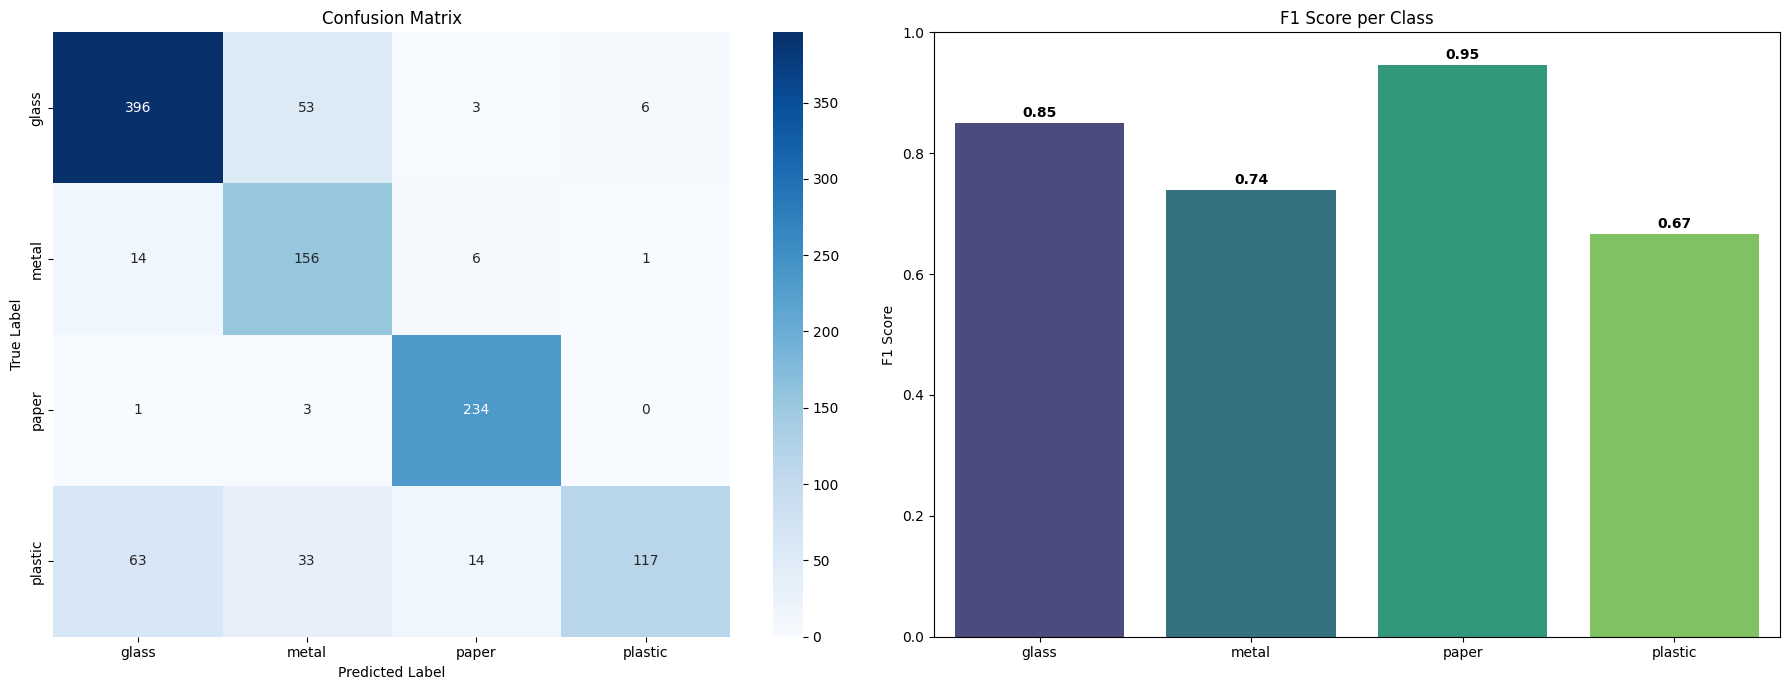

In [119]:
plot_history({
    'train_loss': [x[0] for x in history],
    'val_loss': [x[1] for x in history],
    'train_acc': [],
    'val_acc': []
})
model_1 = RecyclingVGG().to(device)
model_loaded = load_model("model_non_augmented_vgg.pth", model_1)
metrics = evaluate_model(model_loaded, test_dl, device, dataset.classes)

In [14]:
class RecyclingResNet50(nn.Module):
    def __init__(self, num_classes=4, pre_trained=True):
        super(RecyclingResNet50, self).__init__()

        weights = models.ResNet50_Weights.DEFAULT if pre_trained else None
        self.model = models.resnet50(weights=weights)

        for param in self.model.parameters():
             param.requires_grad = False

        num_features = self.model.fc.in_features
        self.model.fc = nn.Linear(num_features, num_classes)

    def forward(self, x):
        return self.model(x)

In [121]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_1 = RecyclingResNet50(num_classes=4).to(device)
optimizer = optim.AdamW(params=model_1.parameters(),lr=0.0005, weight_decay=1e-4)
scaler = torch.cuda.amp.GradScaler()
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=10)

EPOCHS = 150
best_loss = float('inf')
early_stopping_counter = 0
history=[]
for epoch in range(1, EPOCHS + 1):
    train_loss = train_one_epoch(model_1, train_dl, optimizer, epoch, scaler)

    val_loss = validate(model_1, val_dl)

    scheduler.step(val_loss)

    print(f"Epoch {epoch}/{EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

    history.append([train_loss, val_loss])

    if val_loss < best_loss:
        best_loss = val_loss
        early_stopping_counter = 0
        torch.save(model_1.state_dict(), "model_non_augmented_res.pth")
        print("✓ Saved best model")
    else:
        early_stopping_counter += 1
        if early_stopping_counter >= 15:
            print("Early stopping triggered.")
            break

print("Training Complete.")

C:\Users\deniz\AppData\Local\Temp\ipykernel_37040\2129196256.py:4: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
Epoch 1 [Train]: 100%|██████████| 100/100 [00:42<00:00,  2.36it/s, loss=0.503]


Epoch 1/150 | Train Loss: 0.8412 | Val Loss: 0.5581
✓ Saved best model


Epoch 2 [Train]: 100%|██████████| 100/100 [00:41<00:00,  2.41it/s, loss=0.534]


Epoch 2/150 | Train Loss: 0.4858 | Val Loss: 0.4143
✓ Saved best model


Epoch 3 [Train]: 100%|██████████| 100/100 [00:41<00:00,  2.42it/s, loss=0.447]


Epoch 3/150 | Train Loss: 0.3656 | Val Loss: 0.3362
✓ Saved best model


... (70 outputs left out)

Epoch 39 [Train]: 100%|██████████| 100/100 [00:40<00:00,  2.49it/s, loss=0.0301]


Epoch 39/150 | Train Loss: 0.0620 | Val Loss: 0.1889


Epoch 40 [Train]: 100%|██████████| 100/100 [00:40<00:00,  2.49it/s, loss=0.0879]


Epoch 40/150 | Train Loss: 0.0641 | Val Loss: 0.1982
Early stopping triggered.
Training Complete.


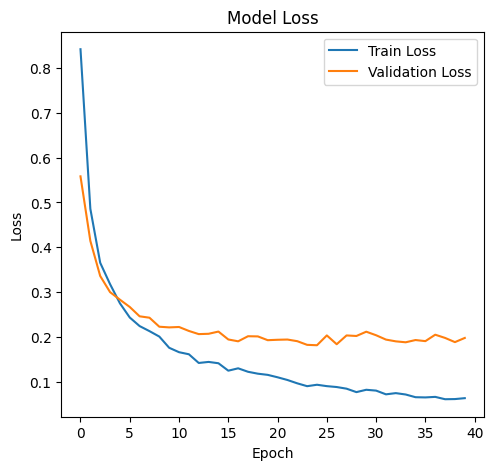

Gathering predictions...

  MODEL EVALUATION REPORT
Global Accuracy: 92.91%
Global F1 Score: 0.9281
----------------------------------------
Classification Report:

              precision    recall  f1-score   support

       glass       0.93      0.96      0.95       458
       metal       0.90      0.91      0.90       177
       paper       0.97      0.99      0.98       238
     plastic       0.91      0.81      0.86       227

    accuracy                           0.93      1100
   macro avg       0.93      0.92      0.92      1100
weighted avg       0.93      0.93      0.93      1100



C:\Users\deniz\AppData\Local\Temp\ipykernel_37040\910868668.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_names, y=class_scores, palette='viridis', ax=axes[1])


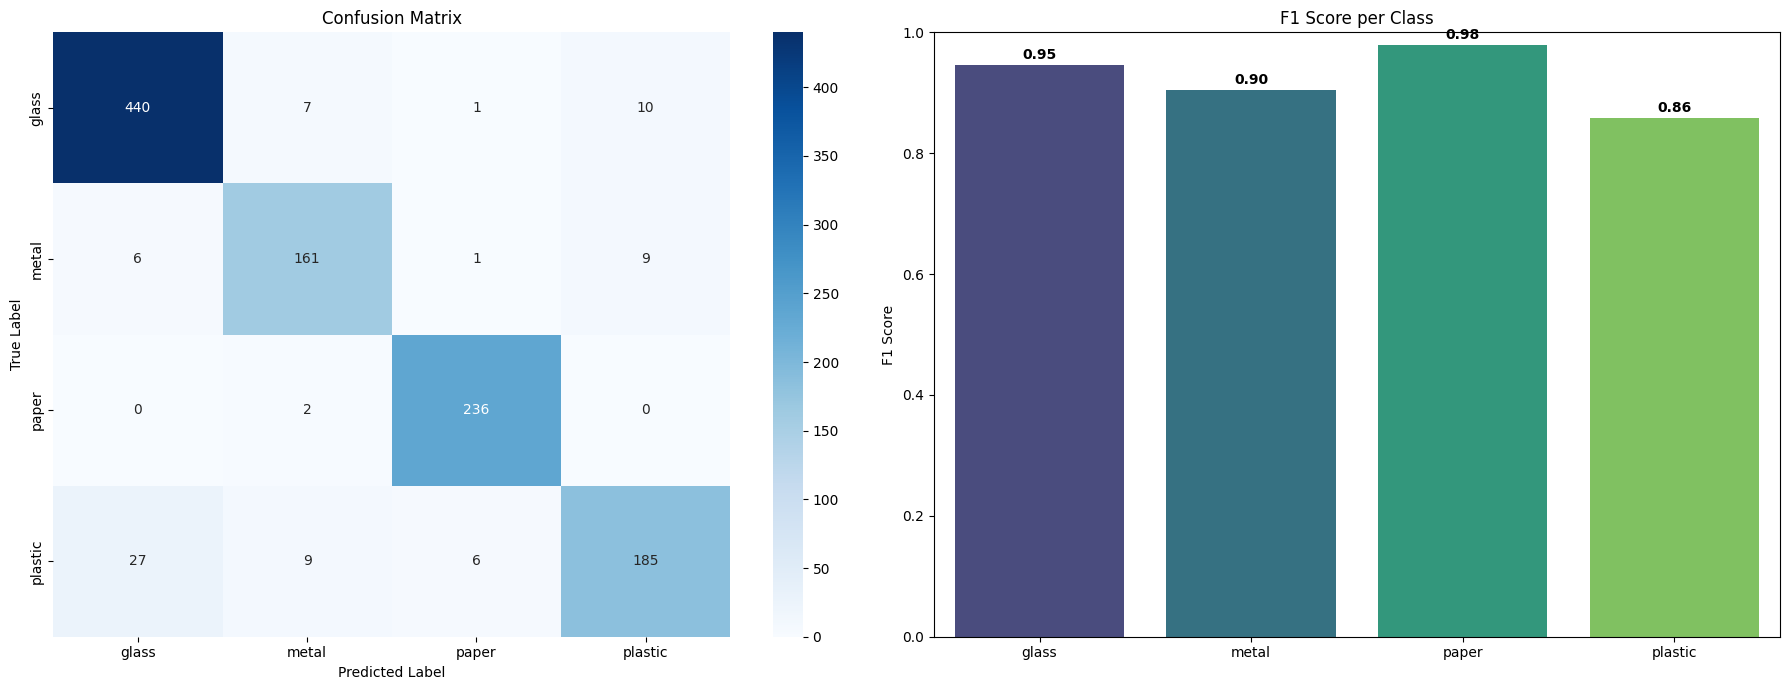

In [122]:
plot_history({
    'train_loss': [x[0] for x in history],
    'val_loss': [x[1] for x in history],
    'train_acc': [],
    'val_acc': []
})
model_1 = RecyclingResNet50().to(device)
model_loaded = load_model("model_non_augmented_res.pth", model_1)
metrics = evaluate_model(model_loaded, test_dl, device, dataset.classes)

In [48]:
import cv2
import numpy as np
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
import torch
import os

def apply_low_light(image_np, brightness_factor=0.2, noise_ratio=0.01):
    hsv = cv2.cvtColor(image_np, cv2.COLOR_RGB2HSV)
    hsv = hsv.astype(np.float32)

    hsv[..., 2] = hsv[..., 2] * brightness_factor
    hsv = np.clip(hsv, 0, 255).astype(np.uint8)

    darkened = cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)

    mask = np.random.rand(*darkened.shape[:2])
    darkened[mask < noise_ratio] = 0
    darkened[mask > (1 - noise_ratio)] = 255

    return darkened

base_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop(227),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

aug_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=30),
    transforms.Resize((256, 256)),
    transforms.CenterCrop(227),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class ExtendedGarbageDataset(Dataset):
    def __init__(self, root_dir, is_train=True):
        self.data = datasets.ImageFolder(root=root_dir)
        self.classes = self.data.classes
        self.is_train = is_train

    def __len__(self):
        if self.is_train:
            return 2 * len(self.data)
        return len(self.data)

    def __getitem__(self, idx):
        original_len = len(self.data)

        if idx >= original_len:
            actual_idx = idx - original_len
            use_augmentation = True
        else:
            actual_idx = idx
            use_augmentation = False

        img_pil, label = self.data[actual_idx]
        img_np = np.array(img_pil)

        low_light_img = apply_low_light(img_np)
        img_pil_dark = Image.fromarray(low_light_img)

        if self.is_train and use_augmentation:
            final_img = aug_transform(img_pil_dark)
        else:
            final_img = base_transform(img_pil_dark)

        return final_img, label

full_raw_data = datasets.ImageFolder(root='garbage_classification')
train_size = int(0.8 * len(full_raw_data))
val_size = int(0.1 * len(full_raw_data))
test_size = len(full_raw_data) - train_size - val_size

generator = torch.Generator().manual_seed(42)
train_dataset_full, val_dataset_full, test_dataset_full = torch.utils.data.random_split(
    full_raw_data, [train_size, val_size, test_size], generator=generator
)

full_train_ds = ExtendedGarbageDataset('garbage_classification', is_train=True)
full_val_test_ds = ExtendedGarbageDataset('garbage_classification', is_train=False)

train_indices = train_dataset_full.indices
doubled_train_indices = train_indices + [i + len(full_raw_data) for i in train_indices]

train_ds = torch.utils.data.Subset(full_train_ds, doubled_train_indices)
val_ds = torch.utils.data.Subset(full_val_test_ds, val_dataset_full.indices)
test_ds = torch.utils.data.Subset(full_val_test_ds, test_dataset_full.indices)

train_dl = DataLoader(train_ds, batch_size=32, shuffle=True)
val_dl = DataLoader(val_ds, batch_size=32, shuffle=False)
test_dl = DataLoader(test_ds, batch_size=32, shuffle=False)

print(f"Classes: {full_train_ds.classes}")
print(f"Train size (Extended): {len(train_ds)}")
print(f"Val size: {len(val_ds)}")
print(f"Test size: {len(test_ds)}")

Classes: ['glass', 'metal', 'paper', 'plastic']
Train size (Extended): 7512
Val size: 469
Test size: 470


--- VISUALIZING AUGMENTED TRAINING DATA ---
Batch Shape: torch.Size([32, 3, 227, 227])
Labels in batch: tensor([2, 2, 0, 1, 2, 0, 0, 0, 2, 1, 1, 0, 3, 3, 0, 1, 2, 0, 3, 1, 0, 2, 3, 2,
        0, 0, 0, 0, 3, 0, 0, 1])


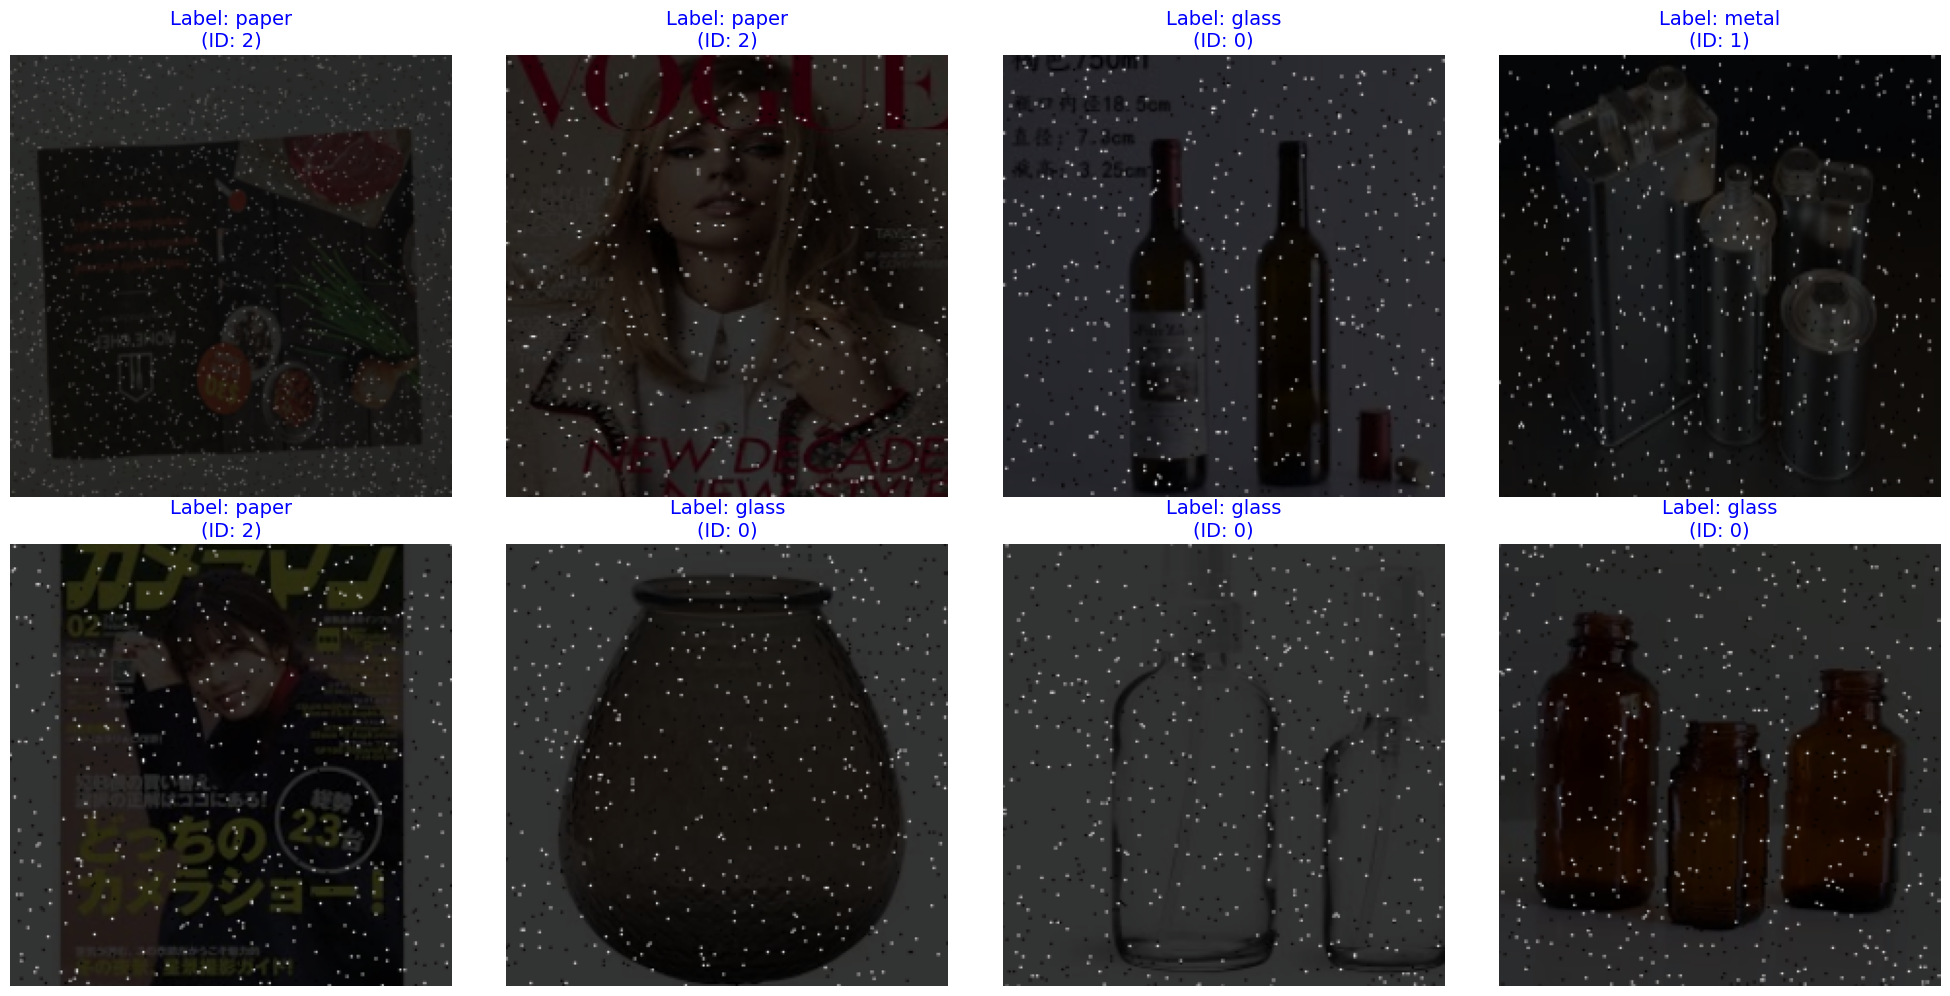

In [49]:
print("--- VISUALIZING AUGMENTED TRAINING DATA ---")
visualize_augmented_batch(train_dl, dataset.classes, count=8)

In [29]:
model_1 = RecyclingCNN().to(device)

optimizer = optim.AdamW(params=model_1.parameters(),lr=0.0005, weight_decay=1e-4)
scaler = torch.cuda.amp.GradScaler()
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=10)

EPOCHS = 150
best_loss = float('inf')
early_stopping_counter = 0
history=[]
for epoch in range(1, EPOCHS + 1):
    train_loss = train_one_epoch(model_1, train_dl, optimizer, epoch, scaler)

    val_loss = validate(model_1, val_dl)

    scheduler.step(val_loss)

    print(f"Epoch {epoch}/{EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

    history.append([train_loss, val_loss])

    if val_loss < best_loss:
        best_loss = val_loss
        early_stopping_counter = 0
        torch.save(model_1.state_dict(), "model_augmented_base.pth")
        print("✓ Saved best model")
    else:
        early_stopping_counter += 1
        if early_stopping_counter >= 15:
            print("Early stopping triggered.")
            break
print("Training Complete.")

C:\Users\deniz\AppData\Local\Temp\ipykernel_24088\3933282046.py:4: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
Epoch 1 [Train]: 100%|██████████| 235/235 [04:37<00:00,  1.18s/it, loss=0.986]


Epoch 1/150 | Train Loss: 1.4761 | Val Loss: 2.1073
✓ Saved best model


Epoch 2 [Train]: 100%|██████████| 235/235 [04:43<00:00,  1.20s/it, loss=1.12] 


Epoch 2/150 | Train Loss: 0.9877 | Val Loss: 2.4225


Epoch 3 [Train]: 100%|██████████| 235/235 [04:42<00:00,  1.20s/it, loss=1.06] 


Epoch 3/150 | Train Loss: 0.8592 | Val Loss: 1.8311
✓ Saved best model


... (18 outputs left out)

Epoch 13 [Train]: 100%|██████████| 235/235 [05:33<00:00,  1.42s/it, loss=0.686]


Epoch 13/150 | Train Loss: 0.4144 | Val Loss: 2.0898


Epoch 14 [Train]:  29%|██▉       | 68/235 [01:34<03:53,  1.40s/it, loss=0.783] 


KeyboardInterrupt: 

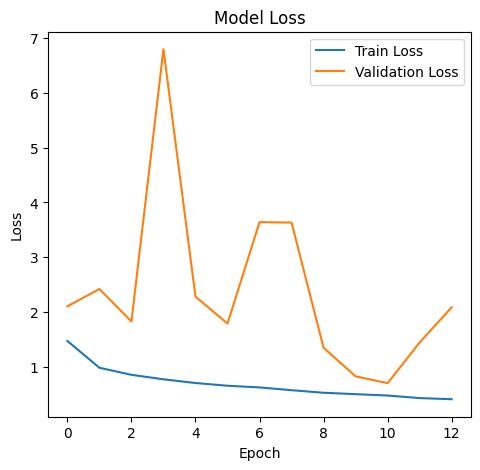

Gathering predictions...

  MODEL EVALUATION REPORT
Global Accuracy: 74.26%
Global F1 Score: 0.7389
----------------------------------------
Classification Report:

              precision    recall  f1-score   support

       glass       0.73      0.92      0.81       193
       metal       0.53      0.62      0.58        64
       paper       0.86      0.58      0.69       105
     plastic       0.88      0.65      0.74       108

    accuracy                           0.74       470
   macro avg       0.75      0.69      0.71       470
weighted avg       0.77      0.74      0.74       470



C:\Users\deniz\AppData\Local\Temp\ipykernel_24088\910868668.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_names, y=class_scores, palette='viridis', ax=axes[1])


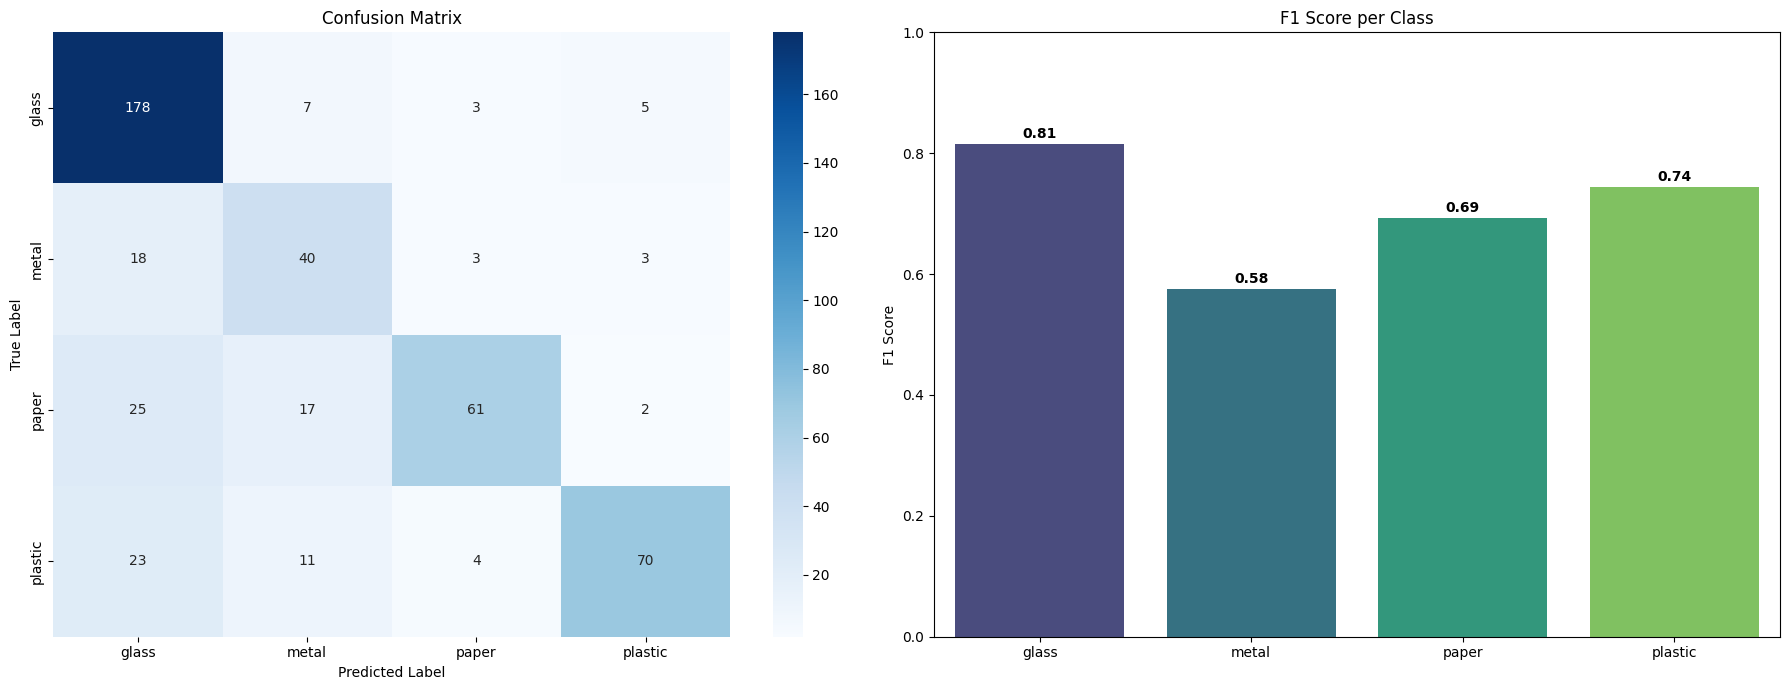

In [30]:
plot_history({
    'train_loss': [x[0] for x in history],
    'val_loss': [x[1] for x in history],
    'train_acc': [],
    'val_acc': []
})
model_1 = RecyclingCNN().to(device)
model_loaded = load_model("model_augmented_base.pth", model_1)
metrics = evaluate_model(model_loaded, test_dl, device, dataset.classes)

In [31]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_1 = RecyclingResNet50(num_classes=4).to(device)
optimizer = optim.AdamW(params=model_1.parameters(),lr=0.0005, weight_decay=1e-4)
scaler = torch.cuda.amp.GradScaler()
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=10)

EPOCHS = 150
best_loss = float('inf')
early_stopping_counter = 0
history=[]
for epoch in range(1, EPOCHS + 1):
    train_loss = train_one_epoch(model_1, train_dl, optimizer, epoch, scaler)

    val_loss = validate(model_1, val_dl)

    scheduler.step(val_loss)

    print(f"Epoch {epoch}/{EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

    history.append([train_loss, val_loss])

    if val_loss < best_loss:
        best_loss = val_loss
        early_stopping_counter = 0
        torch.save(model_1.state_dict(), "model_augmented_res.pth")
        print("✓ Saved best model")
    else:
        early_stopping_counter += 1
        if early_stopping_counter >= 15:
            print("Early stopping triggered.")
            break

print("Training Complete.")

C:\Users\deniz\AppData\Local\Temp\ipykernel_24088\4280958400.py:4: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
Epoch 1 [Train]: 100%|██████████| 235/235 [01:28<00:00,  2.65it/s, loss=0.517]


Epoch 1/150 | Train Loss: 0.8591 | Val Loss: 0.6693
✓ Saved best model


Epoch 2 [Train]: 100%|██████████| 235/235 [01:38<00:00,  2.37it/s, loss=0.325]


Epoch 2/150 | Train Loss: 0.6120 | Val Loss: 0.5402
✓ Saved best model


Epoch 3 [Train]: 100%|██████████| 235/235 [01:39<00:00,  2.37it/s, loss=0.493]


Epoch 3/150 | Train Loss: 0.5250 | Val Loss: 0.5207
✓ Saved best model


... (36 outputs left out)

Epoch 22 [Train]: 100%|██████████| 235/235 [01:16<00:00,  3.06it/s, loss=0.206]


Epoch 22/150 | Train Loss: 0.3325 | Val Loss: 0.3470


Epoch 23 [Train]:   6%|▋         | 15/235 [00:04<00:58,  3.75it/s, loss=0.319]


KeyboardInterrupt: 

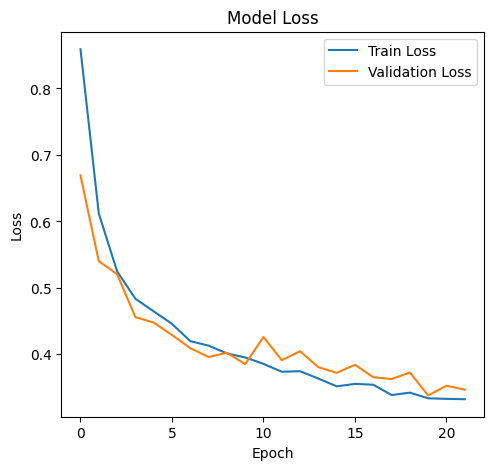

Gathering predictions...

  MODEL EVALUATION REPORT
Global Accuracy: 88.09%
Global F1 Score: 0.8789
----------------------------------------
Classification Report:

              precision    recall  f1-score   support

       glass       0.88      0.95      0.91       193
       metal       0.81      0.75      0.78        64
       paper       0.92      0.94      0.93       105
     plastic       0.88      0.78      0.83       108

    accuracy                           0.88       470
   macro avg       0.87      0.85      0.86       470
weighted avg       0.88      0.88      0.88       470



C:\Users\deniz\AppData\Local\Temp\ipykernel_24088\910868668.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_names, y=class_scores, palette='viridis', ax=axes[1])


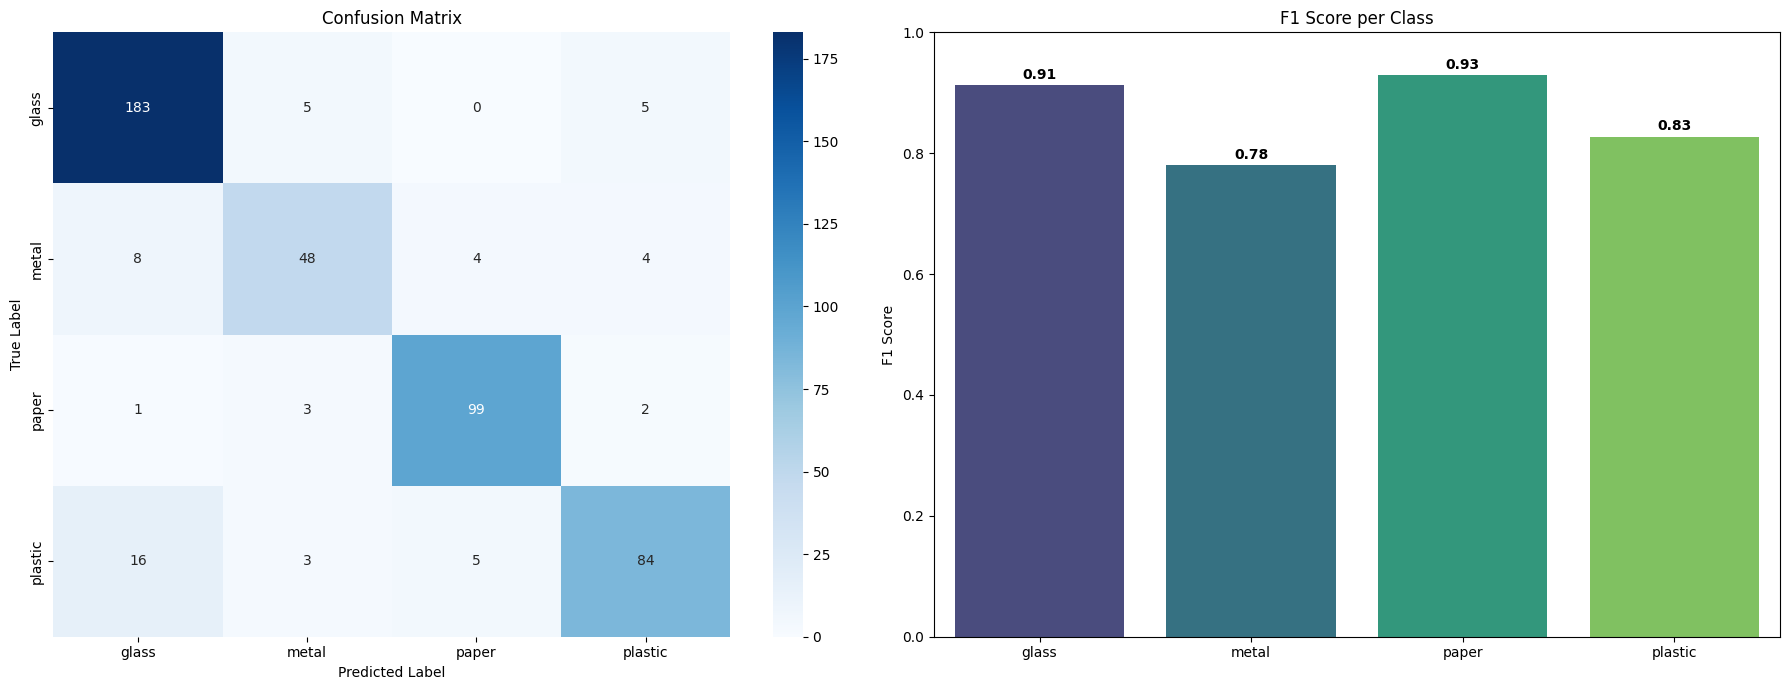

In [32]:
plot_history({
    'train_loss': [x[0] for x in history],
    'val_loss': [x[1] for x in history],
    'train_acc': [],
    'val_acc': []
})
model_1 = RecyclingResNet50().to(device)
model_loaded = load_model("model_augmented_res.pth", model_1)
metrics = evaluate_model(model_loaded, test_dl, device, dataset.classes)

In [33]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_1 = RecyclingVGG(num_classes=4).to(device)
optimizer = optim.AdamW(params=model_1.parameters(),lr=0.0005, weight_decay=1e-4)
scaler = torch.cuda.amp.GradScaler()
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=10)

EPOCHS = 150
best_loss = float('inf')
early_stopping_counter = 0
history=[]
for epoch in range(1, EPOCHS + 1):
    train_loss = train_one_epoch(model_1, train_dl, optimizer, epoch, scaler)

    val_loss = validate(model_1, val_dl)

    scheduler.step(val_loss)

    print(f"Epoch {epoch}/{EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

    history.append([train_loss, val_loss])

    if val_loss < best_loss:
        best_loss = val_loss
        early_stopping_counter = 0
        torch.save(model_1.state_dict(), "model_augmented_vgg.pth")
        print("✓ Saved best model")
    else:
        early_stopping_counter += 1
        if early_stopping_counter >= 15:
            print("Early stopping triggered.")
            break

print("Training Complete.")

C:\Users\deniz\AppData\Local\Temp\ipykernel_24088\2168072423.py:4: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
Epoch 1 [Train]: 100%|██████████| 235/235 [01:16<00:00,  3.07it/s, loss=0.674]


Epoch 1/150 | Train Loss: 0.8771 | Val Loss: 0.8838
✓ Saved best model


Epoch 2 [Train]: 100%|██████████| 235/235 [01:46<00:00,  2.21it/s, loss=0.326]


Epoch 2/150 | Train Loss: 0.6934 | Val Loss: 0.5894
✓ Saved best model


Epoch 3 [Train]: 100%|██████████| 235/235 [01:46<00:00,  2.20it/s, loss=0.646]


Epoch 3/150 | Train Loss: 0.6021 | Val Loss: 0.5571
✓ Saved best model


... (26 outputs left out)

Epoch 17 [Train]: 100%|██████████| 235/235 [01:48<00:00,  2.17it/s, loss=0.0534]


Epoch 17/150 | Train Loss: 0.2909 | Val Loss: 0.7294


Epoch 18 [Train]: 100%|██████████| 235/235 [01:47<00:00,  2.18it/s, loss=0.0883] 


Epoch 18/150 | Train Loss: 0.2611 | Val Loss: 0.8157
Early stopping triggered.
Training Complete.


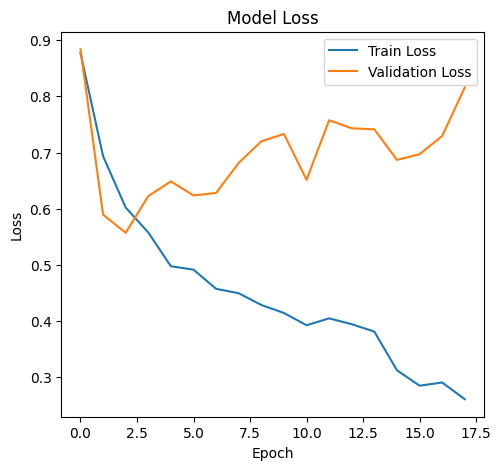

Gathering predictions...



  MODEL EVALUATION REPORT
Global Accuracy: 76.38%
Global F1 Score: 0.7656
----------------------------------------
Classification Report:

              precision    recall  f1-score   support

       glass       0.80      0.81      0.81       193
       metal       0.63      0.67      0.65        64
       paper       0.91      0.82      0.86       105
     plastic       0.66      0.68      0.67       108

    accuracy                           0.76       470
   macro avg       0.75      0.75      0.75       470
weighted avg       0.77      0.76      0.77       470



C:\Users\deniz\AppData\Local\Temp\ipykernel_24088\910868668.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_names, y=class_scores, palette='viridis', ax=axes[1])


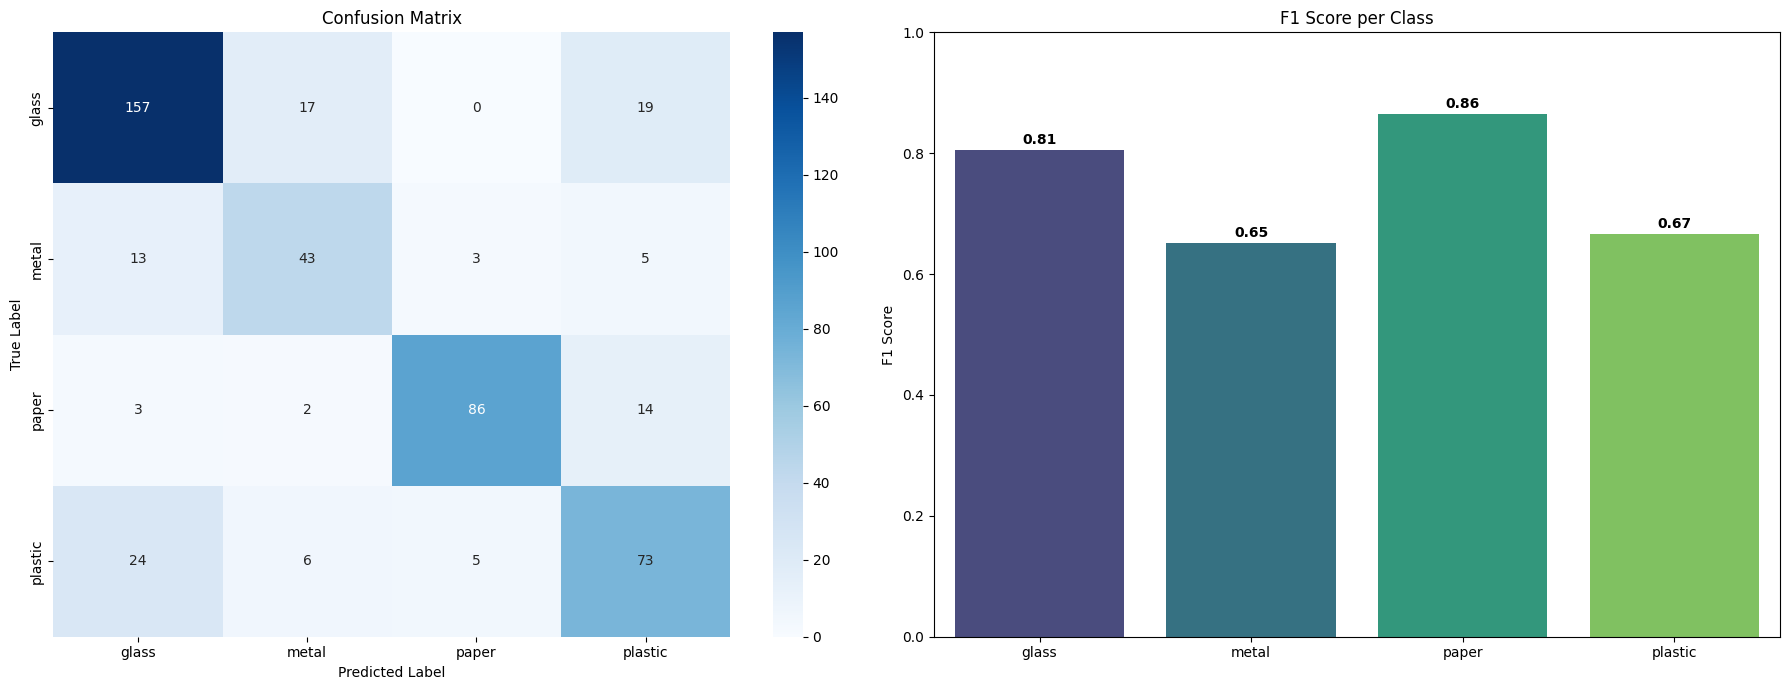

In [34]:
plot_history({
    'train_loss': [x[0] for x in history],
    'val_loss': [x[1] for x in history],
    'train_acc': [],
    'val_acc': []
})
model_1 = RecyclingVGG(num_classes=4).to(device)
model_loaded = load_model("model_augmented_vgg.pth", model_1)
metrics = evaluate_model(model_loaded, test_dl, device, dataset.classes)